## Imports and SLM

In [1383]:
from src.slm_initialise import slm_initialise
from src.utils import *
from src.plots import plot_fit,bb,g,fg
from slmsuite.holography.algorithms import FeedbackHologram
from slmsuite.holography.toolbox import convert_vector
from src.algos import *
from scipy.optimize import curve_fit
import plotly.graph_objects as go
from matplotlib import pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torchmin import minimize
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Display Positions:
#,  Position
0,  x=1920, y=0, width=1280, height=1024
1,  x=0, y=0, width=1920, height=1200 (main)
Initializing pyglet... success
Searching for window with display_number=0... success
Creating window... [Errno 2] No such file or directory: 'C:\\Users\\QC\\Envs\\SLM_new\\Lib\\site-packages\\slmsuite\\hardware\\..\\..\\docs\\source\\static\\slmsuite-notext-16x16.png'
success
Looking for cameras... success
ThorCam sn '12975' initializing... success


smooth:   0%|          | 0/16 [00:00<?, ?it/s]

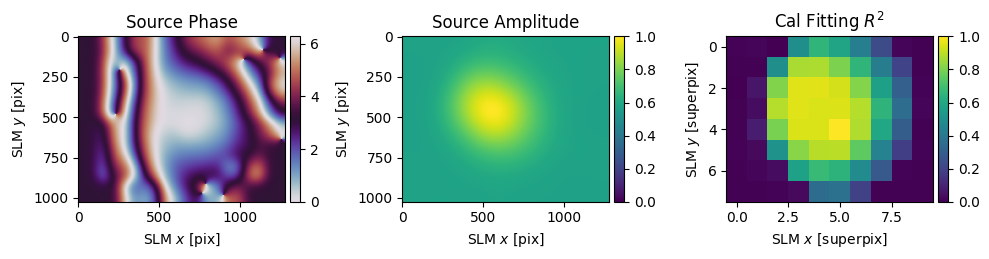

array([[1, 1, 1, ..., 1, 1, 2],
       [1, 1, 1, ..., 1, 2, 1],
       [1, 1, 2, ..., 2, 1, 2],
       ...,
       [1, 2, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 1, 1, 1],
       [1, 1, 1, ..., 2, 2, 2]], dtype=uint16)

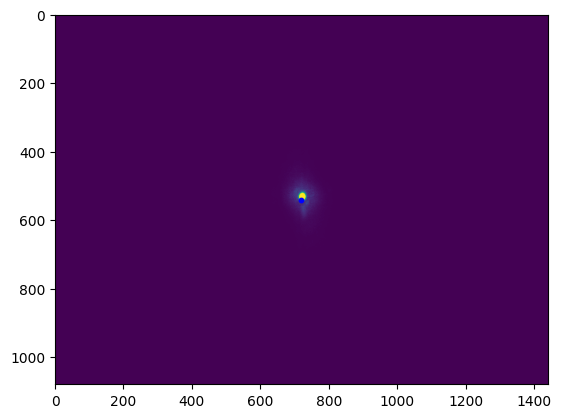

In [1384]:
fs = slm_initialise(force=True,verbose=True)
fs.cam.set_exposure(0.064e-3)
calibrate(fs,vendor = False,refresh = False)
sp_calibrate(fs,refresh=False)
plot_cam(fs,phase="zero",centre=True, save=True)

In [221]:
fs.cam.set_exposure(0.0001)

0.000113

In [222]:
fs.cam.live()

Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x05\xa0\x00\x00\x048\x08\x06\x00\x00\x00\xff\xe2{R\x…

## SLM input

optimised params are [4.27754945e-01 2.53538014e+02 4.56084865e+02 5.68895209e+02
 5.73563824e-01]


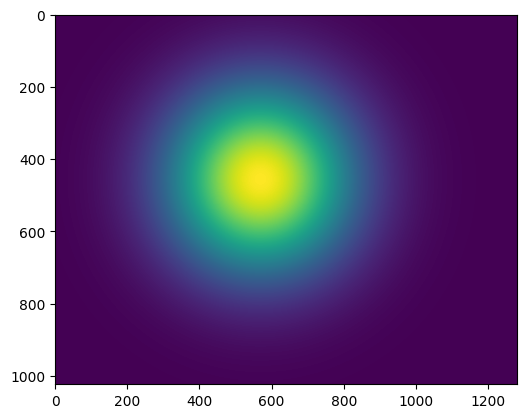

In [158]:
plot_fit(fs.slm.source['amplitude'],'g')

## BB params get

In [4]:
toolbox.convert_vector(fs.ijcam_to_kxyslm(([0,1,1,0],[0,0,1,1])),from_units='kxy',to_units='knm',hardware = fs) - toolbox.convert_vector(fs.ijcam_to_kxyslm([0,0]),from_units='kxy',to_units='knm',hardware = fs)

NameError: name 'fs' is not defined

In [5]:
nm_scale = ((0.14197579**2 + 0.10442282**2)/2)**0.5
nm_scale

0.12462192881446768

In [1026]:
toolbox.convert_vector(fs.ijcam_to_kxyslm(([1180],[230])),from_units='kxy',to_units='knm',hardware = fs)

array([[601.26771886],
       [563.10850778]])

In [6]:
bb_img = np.load('C:/Users/QC/Documents/GitHub/holography/figures/raw/bbs_24_59_corr.npy')

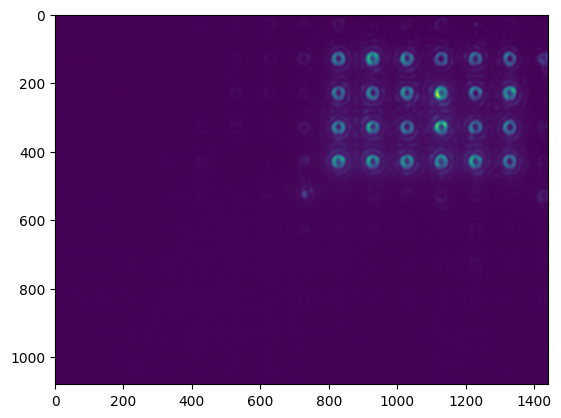

In [255]:
plt.imshow(bb_img)

In [1187]:
def bb_new(xdata,A,w,xc,yc,offset):
    x = xdata[0]
    y = xdata[1]
    "bottle beam function"
    Amp = (8* (w**4)/np.pi)**0.5
    I = A*Amp*((x-xc)**2 + (y-yc)**2)*np.e**(-((x-xc)**2+(y-yc)**2)/w**2) + offset
    return I
def periodic_bb_fit(xdata, A, w, xc, yc, offset,p):
    x = xdata[0]
    y = xdata[1]
    theta = np.arctan2(y - yc, x - xc)
    I = A * ((x - xc)**2 + (y - yc)**2) * np.exp(-((x - xc)**2 + (y - yc)**2) / w**2)*(1 + 0.3*np.cos(3 * theta + p)**2) + offset
    return I
def plot_fit_bb(target):
    f_fit = bb_new
    xdata = np.array([[i,j] for i in range(target.shape[0]) for j in range(target.shape[1])]).T
    initial_guess = (target.max() - target.min(),10,target.shape[0]/2,target.shape[1]/2,target.min())
    popt, pcov = curve_fit(f_fit,xdata,target[*xdata],p0=initial_guess,maxfev=10000)
    # popt = initial_guess
    print(f"optimised params are {popt}")

    "fitted image"
    pred = f_fit(xdata, *popt).reshape(target.shape[0],target.shape[1])

    "matplotlib 2d plot"
    plt.imshow(pred)
    
    "plotly 3d plot"
    "original bb as scatter plot"
    scatter_plot = go.Scatter3d(
        x=xdata[0],
        y=xdata[1],
        z=target[*xdata],
        mode='markers',
        marker=dict(size=1, color='blue'),
        name='Target bottle beam'
    )
    "fitted bb as surface plot"
    surface_plot = go.Surface(
    x=xdata[0].reshape(target.shape[0],target.shape[1]),
    y=xdata[1].reshape(target.shape[0],target.shape[1]),
    z=pred,
    colorscale='YlOrRd',
    opacity=0.7,
    name='Predicted Surface'
    )

    "Combine plots"
    fig = go.Figure(data=[scatter_plot, surface_plot])
    fig.update_layout(
        scene=dict(
            xaxis_title='X',
            yaxis_title='Y',
            zaxis_title='Z',
        ),
        title='3D Curve Fit Plot in Plotly'
    )

    fig.show()

def plot_fit_periodic_bb(target):
    f_fit = periodic_bb_fit
    xdata = np.array([[i,j] for i in range(target.shape[0]) for j in range(target.shape[1])]).T
    initial_guess = (target.max() - target.min(),10,target.shape[0]/2,target.shape[1]/2,target.min(),0)
    popt, pcov = curve_fit(f_fit,xdata,target[*xdata],p0=initial_guess,maxfev=10000)
    # popt = initial_guess
    print(f"optimised params are {popt}")

    "fitted image"
    pred = f_fit(xdata, *popt).reshape(target.shape[0],target.shape[1])

    "matplotlib 2d plot"
    plt.imshow(pred)
    
    "plotly 3d plot"
    "original bb as scatter plot"
    scatter_plot = go.Scatter3d(
        x=xdata[0],
        y=xdata[1],
        z=target[*xdata],
        mode='markers',
        marker=dict(size=1, color='blue'),
        name='Target bottle beam'
    )
    "fitted bb as surface plot"
    surface_plot = go.Surface(
    x=xdata[0].reshape(target.shape[0],target.shape[1]),
    y=xdata[1].reshape(target.shape[0],target.shape[1]),
    z=pred,
    colorscale='YlOrRd',
    opacity=0.7,
    name='Predicted Surface'
    )

    "Combine plots"
    fig = go.Figure(data=[scatter_plot, surface_plot])
    fig.update_layout(
        scene=dict(
            xaxis_title='X',
            yaxis_title='Y',
            zaxis_title='Z',
        ),
        title='3D Curve Fit Plot in Plotly'
    )

    fig.show()

optimised params are [1.64295575e-03 1.21222547e+01 4.98946331e+01 4.76537396e+01
 2.63635799e+00]


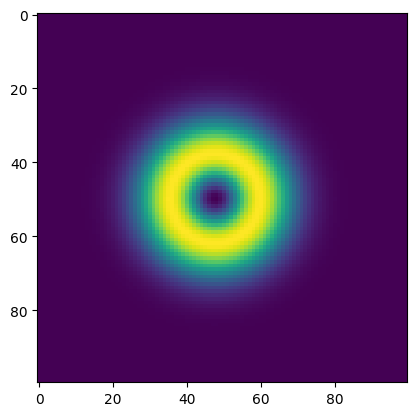

In [1188]:
plot_fit_bb(target = bb_img[130-50:130+50,830-50:830+50])

## create target and input

In [1389]:
pad_factor = 8

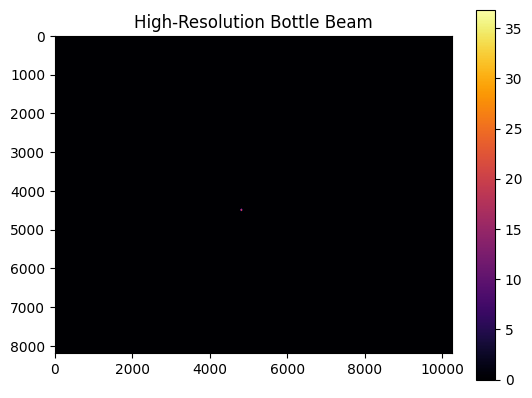

In [1390]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import zoom

# Original resolution
H, W = 1024, 1280

# Higher resolution factor
H_hr = H * pad_factor
W_hr = W * pad_factor

# Normal coordinate grid
x = np.arange( W)
y = np.arange(H)
X, Y = np.meshgrid(x, y)

# High-res coordinate grid
x_hr = np.arange( W_hr)
y_hr = np.arange(H_hr)
X_hr, Y_hr = np.meshgrid(x_hr, y_hr)

# Beam parameters
A = 0.38526713
w = 7.07*pad_factor/4   # adjust width to match scale
# xc = W_hr / 2
# yc = H_hr / 2
xc = 601*pad_factor
yc = 563*pad_factor
offset = 0

# Bottle beam function
def bb_new(xdata, A, w, xc, yc, offset):
    x = xdata[0]
    y = xdata[1]
    I = A * ((x - xc)**2 + (y - yc)**2) * np.exp(-((x - xc)**2 + (y - yc)**2) / w**2) + offset
    return I



# High-res target
target_hr = periodic_bb_fit((X_hr, Y_hr), A, w, xc, yc, offset,5)

# Visualize high-res beam
plt.imshow(target_hr, cmap='inferno')
plt.colorbar()
plt.title('High-Resolution Bottle Beam')
plt.show()


In [1391]:
A_target = target_hr/FeedbackHologram._norm(target_hr)

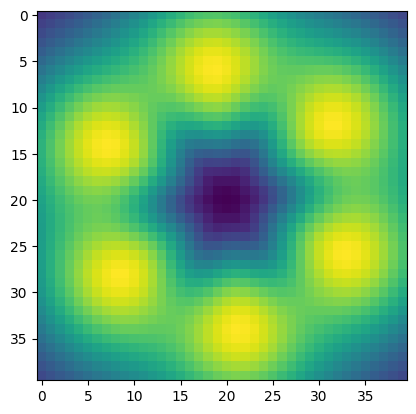

In [1392]:
plt.imshow(A_target[yc-20:yc+20,xc-20:xc+20])

In [1393]:
# A_input_gauss = fg((X, Y), 4.27754945e-01, 2.53538014e+02, W / 2, H / 2, 5.73563824e-01)
A_input_gauss = fg((X, Y), 4.27754945e-01, 2.53538014e+02, W / 2, H / 2, 0)
 

In [1394]:
def downsample_phase(phi_hr, scale):
    # phi_hr is 2D tensor (H, W)
    phi_hr = phi_hr.unsqueeze(0).unsqueeze(0)  # shape -> (1, 1, H, W)
    phi_lr = F.avg_pool2d(phi_hr, kernel_size=scale, stride=scale)
    phi_lr = phi_lr.squeeze(0).squeeze(0)  # back to 2D (H/scale, W/scale)
    return phi_lr

def repeat_upsample(phi_lr, scale):
    # phi_lr shape: (H, W)
    phi_lr = phi_lr.unsqueeze(0).unsqueeze(0)  # add batch and channel dims -> (1,1,H,W)
    
    # Repeat each row and column 'scale' times
    phi_hr = phi_lr.repeat_interleave(scale, dim=2).repeat_interleave(scale, dim=3)
    
    return phi_hr.squeeze(0).squeeze(0)

def gs_new(A_target,n_iters = 500):
    H, W = 1024, 1280
    pad_H = H * pad_factor
    pad_W = W * pad_factor

    A_t = A_target
    crop_y = slice((pad_H - H) // 2, (pad_H + H) // 2)
    crop_x = slice((pad_W - W) // 2, (pad_W + W) // 2)
    phi_nf = torch.zeros((pad_H, pad_W))
    # phi_nf[crop_y,crop_x] = phi_bb
    # input_beam = fs.slm.source['amplitude']
    # input_beam = np.ones(tuple(x * pad_factor for x in fs.slm.shape))
    input_beam = A_input_gauss
    A_input_norm = torch.tensor(input_beam / FeedbackHologram._norm(input_beam), dtype=torch.float32)
    A_input = torch.nn.functional.pad(A_input_norm, (
        (pad_W - W) // 2, (pad_W - W + 1) // 2,
        (pad_H - H) // 2, (pad_H - H + 1) // 2
    ))
    F_ff = None
    phi_nf_avg = phi_nf

    

    for iter in range(n_iters):
        field_nf = A_input * torch.exp(1j * phi_nf)
        F_ff = torch.fft.fftshift(torch.fft.fft2(torch.fft.fftshift(field_nf), norm='ortho'))
        A_ff = torch.abs(F_ff)
        phi_ff = torch.angle(F_ff)

        # Apply amplitude constraint in Fourier domain
        F_nf = torch.fft.ifftshift(torch.fft.ifft2(torch.fft.ifftshift(A_t * torch.exp(1j * phi_ff)), norm='ortho'))
        A_nf = torch.abs(F_nf)
        phi_nf = torch.angle(F_nf)
        # phi_nf_lr = downsample_phase(phi_nf,pad_factor)
        # phi_nf_avg = repeat_upsample(phi_nf_lr,pad_factor)
        # Optional loss computation
        mse = torch.nn.functional.mse_loss(
            A_ff, A_target
        ).item() * H * W
        print(mse)
    phi_nf_cropped = phi_nf[crop_y, crop_x]
    return A_ff,phi_nf_cropped

In [1395]:
A_ff,phi_nf = gs_new(torch.tensor(A_target))

KeyboardInterrupt: 

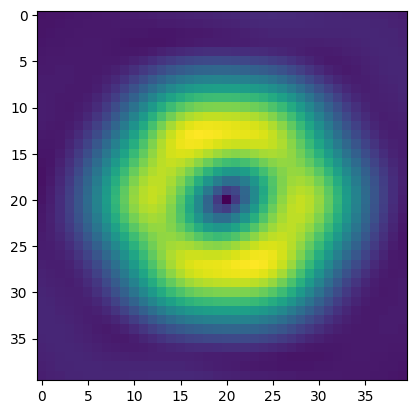

In [1316]:
plt.imshow(A_ff[yc-20:yc+20,xc-20:xc+20])


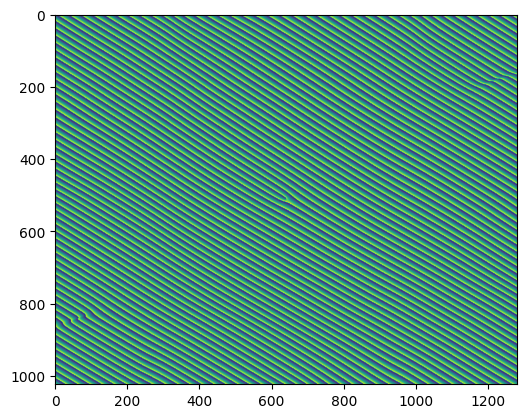

In [1317]:
plt.imshow(phi_nf)

In [ ]:
# np.save(f"{figures_path/'raw'/"periodic_bb_gs500"}.npy", A_ff)
# np.save(f"{figures_path/'raw'/"periodic_bb_gs500_phase"}.npy", phi_nf)

In [1265]:
def get_farfield(phi_nf,pad_factor,crop = True):
    H, W = 1024, 1280
    pad_H = H * pad_factor
    pad_W = W * pad_factor
    input_beam = A_input_gauss
    A_input_norm = torch.tensor(input_beam / FeedbackHologram._norm(input_beam), dtype=torch.float32)
    A_input = torch.nn.functional.pad(A_input_norm, (
        (pad_W - W) // 2, (pad_W - W + 1) // 2,
        (pad_H - H) // 2, (pad_H - H + 1) // 2
    ))
    phi_nf_pad = torch.nn.functional.pad(phi_nf, (
        (pad_W - W) // 2, (pad_W - W + 1) // 2,
        (pad_H - H) // 2, (pad_H - H + 1) // 2
    ))
    field_nf = A_input * torch.exp(1j * phi_nf_pad)
    F_ff = torch.fft.fftshift(torch.fft.fft2(torch.fft.fftshift(field_nf), norm='ortho'))
    A_ff = torch.abs(F_ff)
    phi_ff = torch.angle(F_ff)
    crop_y = slice((pad_H - H) // 2, (pad_H + H) // 2)
    crop_x = slice((pad_W - W) // 2, (pad_W + W) // 2)
    if crop == True:
        return  A_ff[crop_y, crop_x]
    else:
        return  A_ff
    

C:\Users\QC\AppData\Local\Temp\ipykernel_8092\1963519357.py:1: UserWarning:

To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).



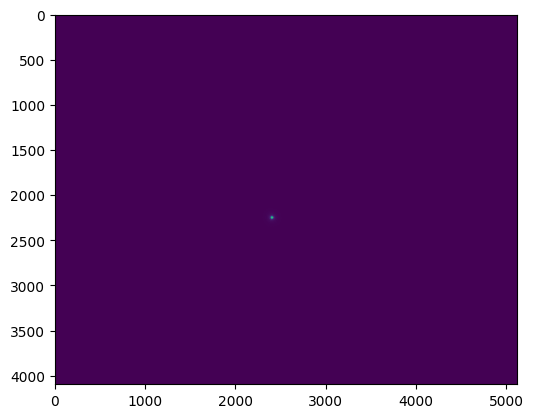

In [1266]:
A_out = get_farfield(torch.tensor(phi_nf),pad_factor=4,crop=False)
plt.imshow(A_out)


In [1267]:
# import numpy as np
# from scipy.fft import fft2, ifft2, fftshift, ifftshift
# from scipy.optimize import minimize

# def cg_phase_retrieval(A_target, A_input_gauss, pad_factor=1, n_iters=100):
#     H, W = 1024, 1280
#     pad_H = H * pad_factor
#     pad_W = W * pad_factor

#     # Normalize and pad input amplitude
#     A_input_norm = A_input_gauss / np.linalg.norm(A_input_gauss)
#     A_input = np.pad(A_input_norm, (
#         ((pad_H - H) // 2, (pad_H - H + 1) // 2),
#         ((pad_W - W) // 2, (pad_W - W + 1) // 2)
#     ))

#     # Also pad the target
#     A_t = A_target

#     crop_y = slice((pad_H - H) // 2, (pad_H + H) // 2)
#     crop_x = slice((pad_W - W) // 2, (pad_W + W) // 2)

#     def loss(phi_crop_flat):
#         phi_crop = phi_crop_flat.reshape(H, W)

#         # Embed into full padded phase
#         phi_full = np.zeros((pad_H, pad_W))
#         phi_full[crop_y, crop_x] = phi_crop

#         field = A_input * np.exp(1j * phi_full)
#         F = fftshift(fft2(fftshift(field), norm='ortho'))
#         A_ff = np.abs(F)

#         return 0.5 * np.sum((A_ff - A_t)**2)*H*W

#     def grad(phi_crop_flat):
#         phi_crop = phi_crop_flat.reshape(H, W)

#         # Embed into full padded phase
#         phi_full = np.zeros((pad_H, pad_W))
#         phi_full[crop_y, crop_x] = phi_crop

#         field = A_input * np.exp(1j * phi_full)
#         F = fftshift(fft2(fftshift(field), norm='ortho'))
#         A_ff = np.abs(F)
#         F_norm = F / (A_ff + 1e-8)

#         diff = (A_ff - A_t) * F_norm
#         back = ifftshift(ifft2(ifftshift(diff), norm='ortho'))
#         grad_phi_full = np.imag(np.conj(field) * back)

#         # Extract gradient only for the cropped phase
#         grad_phi_crop = grad_phi_full[crop_y, crop_x]
#         return grad_phi_crop.ravel()

#     # Initial cropped phase
#     # phi0 = np.zeros((H, W))
#     phi0 = np.random.uniform(0, 2 * np.pi, size=(H, W))
#     res = minimize(
#         loss,
#         phi0.ravel(),
#         method='CG',
#         jac=grad,
#         options={'gtol': 1e-10,'maxiter': n_iters, 'disp': True}
#     )
#     phi_crop_final = res.x.reshape(H, W)
#     phi_full_final = np.zeros((pad_H, pad_W))
#     phi_full_final[crop_y, crop_x] = phi_crop_final


#     final_field = A_input * np.exp(1j * phi_full_final)
#     final_FF = fftshift(fft2(fftshift(final_field), norm='ortho'))
#     A_ff_final = np.abs(final_FF)
#     print("Initial loss:", loss(phi0.ravel()))
#     print("Initial grad norm:", np.linalg.norm(grad(phi0.ravel())))

#     return A_ff_final[crop_y, crop_x], phi_crop_final


In [1268]:
# A_cg,phi_cg = cg_phase_retrieval(A_target,A_input_gauss,pad_factor,500)

In [1269]:
# plt.imshow(A_cg[480:540,600:680])

In [1270]:
# H, W = 1024, 1280
# pad_H = H * pad_factor
# pad_W = W * pad_factor
# crop_y = slice((pad_H - H) // 2, (pad_H + H) // 2)
# crop_x = slice((pad_W - W) // 2, (pad_W + W) // 2)
# plt.imshow(A_target[crop_y, crop_x][480:540,600:680])

In [1271]:
# A_out = get_farfield(torch.tensor(phi_cg),pad_factor=8)
# plt.imshow(A_out[480:540,600:680])

In [1272]:
# plt.imshow(phi_cg)

In [1273]:
# plot_cam(fs=fs,phase=phi_nf.numpy())

In [ ]:
# fs.slm.source['amplitude'].shape

(1024, 1280)

In [ ]:
# np.ones(fs.slm.shape).shape

(1024, 1280)

In [580]:
phi_bb = torch.tensor(np.array([[np.pi if ((i-512)**2 + (j-640)**2) <= 200**2 else 0 for j in range(1280)] for i in range(1024)]))

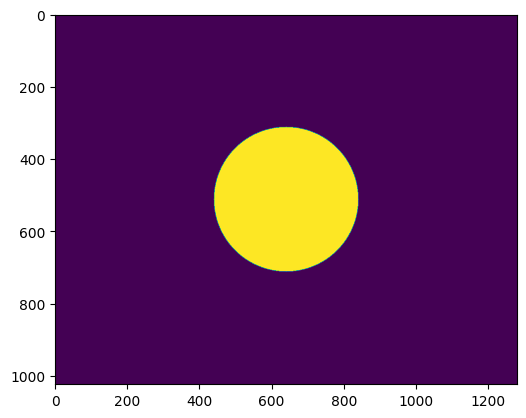

In [577]:
plt.imshow(phi_bb.numpy())

In [956]:
W,xc/pad_factor

(1280, 1180.0)

In [1396]:
import torch
import torch.fft


def get_radius_map(H, W, device):
    # y = torch.arange(H, device=device) - H // 2
    # x = torch.arange(W, device=device) - W // 2
    y = torch.arange(H, device=device) - yc
    x = torch.arange(W, device=device) - xc
    yy, xx = torch.meshgrid(y, x, indexing='ij')
    radius_map = torch.sqrt(xx**2 + yy**2)
    radius_map /= radius_map.max()  # normalize to [0, 1]
    return radius_map

def make_circular_weight(H, W, center=None, radius=50, high=1.0, low=0.1, device='cpu'):
    if center is None:
        center = (yc,xc)
    y = torch.arange(H, device=device).view(-1, 1)
    x = torch.arange(W, device=device).view(1, -1)
    dist2 = (x - center[1])**2 + (y - center[0])**2
    mask = torch.where(dist2 <= radius**2, high, low)
    return mask
def make_gaussian_weight(H, W, center=None, sigma=30, high=1.0, low=0.1, device='cpu'):
    if center is None:
        center = (yc,xc)
    y = torch.arange(H, device=device).view(-1, 1)
    x = torch.arange(W, device=device).view(1, -1)
    dist2 = (x - center[1])**2 + (y - center[0])**2
    weight = low + (high - low) * torch.exp(-dist2 / (2 * sigma**2))
    return weight




def cg_phase_retrieval_torch_cg(A_target_np, A_input_gauss_np, pad_factor=1, n_iters=100, device='cpu'):
    H, W = A_input_gauss_np.shape
    pad_H, pad_W = H * pad_factor, W * pad_factor

    crop_y = slice((pad_H - H) // 2, (pad_H + H) // 2)
    crop_x = slice((pad_W - W) // 2, (pad_W + W) // 2)

    # Convert to torch tensors
    A_target = torch.tensor(A_target_np, dtype=torch.float32, device=device)
    A_input_gauss = torch.tensor(A_input_gauss_np, dtype=torch.float32, device=device)

    # Normalize and pad input amplitude
    A_input_norm = A_input_gauss / torch.norm(A_input_gauss)
    A_input = torch.zeros((pad_H, pad_W), dtype=torch.float32, device=device)
    A_input[crop_y, crop_x] = A_input_norm

    # Pad target
    # A_t = torch.zeros((pad_H, pad_W), dtype=torch.float32, device=device)
    # A_t[crop_y, crop_x] = A_target
    A_t = A_target

    # Initialize phase
    phi_crop = torch.rand((H, W), dtype=torch.float32, device=device) * 2 * torch.pi
    # phi_crop = torch.tensor(phi_bb, dtype=torch.float32, device=device, requires_grad=True)
    phi_crop.requires_grad = True
    radius_map = get_radius_map(pad_H, pad_W, device)
    # Weight map: higher weight at center (inverted radius map)
    # weight_map = 1.0 - radius_map  # values ∈ [0, 1], center = 1
    # weight_map = weight_map**5  # Optional: emphasize even more
    weight_map = make_gaussian_weight(pad_H,pad_W,sigma = w*5)

    def evaluate_loss(phi_crop_var):
        phi_full = torch.zeros((pad_H, pad_W), dtype=torch.float32, device=device)
        phi_full[crop_y, crop_x] = phi_crop_var
        field = A_input * torch.exp(1j * phi_full)
        F = torch.fft.fftshift(torch.fft.fft2(torch.fft.fftshift(field), norm='ortho'))
        A_ff = torch.abs(F)
        phi_flip = torch.flip(phi_crop_var, dims=[0, 1])
        error = (A_ff**2 - A_t**2) ** 2
        loss = 0.5 * torch.sum(error) * H * W 
        return loss
    loss_history = []
    # Initial loss and gradient
    loss = evaluate_loss(phi_crop)
    loss.backward()
    grad = phi_crop.grad.detach()
    direction = -grad.clone()
    loss_history.append(loss.item())
    alpha = 1000
    for iter in range(n_iters):
        # Line search (simple backtracking)
        phi_old = phi_crop.data.clone()
        loss_old = loss.item()
        while True:
            phi_crop.data = phi_old + alpha * direction
            loss_new = evaluate_loss(phi_crop)
            print(alpha,torch.norm(grad),loss_new.item())
            if loss_new < loss_old:
                break
            alpha *= 0.7
            if alpha < 1e-6:
                break

        # Compute new gradient
        phi_crop.grad.zero_()
        loss = evaluate_loss(phi_crop)
        loss.backward()
        grad_new = phi_crop.grad.detach()
        loss_history.append(loss.item())
        # Polak–Ribiere beta update
        beta = torch.sum(grad_new * (grad_new - grad)) / (torch.sum(grad * grad) + 1e-12)
        beta = torch.clamp(beta, min=0.0)  # ensure CG direction

        direction = -grad_new + beta * direction
        grad = grad_new

        print(f"[{iter+1:03d}] loss = {loss.item():.7e}, alpha = {alpha:.6e}, beta = {beta:.6e}")

    # Final output
    phi_final = phi_crop.detach().cpu().numpy()
    with torch.no_grad():
        phi_full = torch.zeros((pad_H, pad_W), dtype=torch.float32, device=device)
        phi_full[crop_y, crop_x] = phi_crop
        final_field = A_input * torch.exp(1j * phi_full)
        final_FF = torch.fft.fftshift(torch.fft.fft2(torch.fft.fftshift(final_field), norm='ortho'))
        A_ff_final = torch.abs(final_FF)[crop_y, crop_x].cpu().numpy()

    return A_ff_final, phi_final,loss_history


In [1374]:
import torch

def get_radius_map(H, W, device):
    y = torch.arange(H, device=device) - H // 2
    x = torch.arange(W, device=device) - W // 2
    yy, xx = torch.meshgrid(y, x, indexing='ij')
    radius = torch.sqrt(xx**2 + yy**2)
    radius /= radius.max()  # normalize to [0, 1]
    return radius




def cg_phase_retrieval_radial_torch_cg(A_target_np, A_input_gauss_np, pad_factor=1, n_iters=100, num_bins=128, device='cpu'):
    H, W = A_input_gauss_np.shape
    pad_H, pad_W = H * pad_factor, W * pad_factor

    crop_y = slice((pad_H - H) // 2, (pad_H + H) // 2)
    crop_x = slice((pad_W - W) // 2, (pad_W + W) // 2)

    # Convert to torch tensors
    A_target = torch.tensor(A_target_np, dtype=torch.float32, device=device)
    A_input_gauss = torch.tensor(A_input_gauss_np, dtype=torch.float32, device=device)

    # Normalize and pad input amplitude
    A_input_norm = A_input_gauss / torch.norm(A_input_gauss)
    A_input = torch.zeros((pad_H, pad_W), dtype=torch.float32, device=device)
    A_input[crop_y, crop_x] = A_input_norm

    A_t = A_target
    radius_map = get_radius_map(H, W, device)
    radius_scaled = radius_map * (num_bins - 1)

    r_floor = radius_scaled.floor().long()
    r_ceil = (r_floor + 1).clamp(max=num_bins - 1)
    r_nearest = radius_scaled.round().long().clamp(0, num_bins - 1)
    alpha = radius_scaled - r_floor  # shape [H, W]

    # Optimized variables: phi_r instead of phi_crop
    phi_bb_r = torch.tensor(np.array([np.pi if i <= num_bins/5 else 0  for i in range(num_bins)]))
    phi_r = torch.rand(num_bins, dtype=torch.float32, device=device) * 2 * torch.pi
    # phi_r = torch.tensor(phi_bb_r, dtype=torch.float32, device=device, requires_grad=True)
    phi_r.requires_grad = True
    grad_old = 0
    def build_phi_crop(phi_r):
        """Build radial phase map from phi_r using linear interpolation"""
        # phi_crop = (1 - alpha) * phi_r[r_floor] + alpha * phi_r[r_ceil]
        phi_crop = phi_r[r_nearest]
        return phi_crop

    def evaluate_loss(phi_r_var):
        phi_crop = build_phi_crop(phi_r_var)
        phi_full = torch.zeros((pad_H, pad_W), dtype=torch.float32, device=device)
        phi_full[crop_y, crop_x] = phi_crop

        field = A_input * torch.exp(1j * phi_full)
        F = torch.fft.fftshift(torch.fft.fft2(torch.fft.fftshift(field), norm='ortho'))
        A_ff = torch.abs(F)

        loss = 0.5 * torch.sum((A_ff - A_t) ** 2) * H * W
        return loss

    loss_history = []

    # Initial loss and gradient
    loss = evaluate_loss(phi_r)
    loss.backward()
    grad = phi_r.grad.detach()
    direction = -grad.clone()
    loss_history.append(loss.item())
    alpha_ls = 0.5*1e-3
    for iter in range(n_iters):
        # Backtracking line search
        phi_old = phi_r.data.clone()
        loss_old = loss.item()
        while True:
            phi_r.data = phi_old + alpha_ls * direction
            loss_new = evaluate_loss(phi_r)
            print(alpha_ls,torch.norm(grad),loss_new.item())
            if loss_new < loss_old:
                break
            
            alpha_ls *= 0.9
            if alpha_ls < 1e-6:
                break

        # Compute new gradient
        phi_r.grad.zero_()
        loss = evaluate_loss(phi_r)
        loss.backward()
        grad_new = phi_r.grad.detach()
        loss_history.append(loss.item())

        # Polak–Ribiere update
        beta = torch.sum(grad_new * (grad_new - grad)) / (torch.sum(grad * grad) + 1e-12)
        beta = torch.clamp(beta, min=0.0)

        direction = -grad_new + beta * direction
        grad = grad_new
        if abs(torch.norm(grad) - grad_old) < 5:
            alpha_ls = alpha_ls/0.9
        grad_old = torch.norm(grad)
        print(f"[{iter+1:03d}] loss = {loss.item():.7e}, alpha = {alpha_ls:.6e}, beta = {beta:.6e}")

    # Final output
    phi_crop_final = build_phi_crop(phi_r.detach())
    with torch.no_grad():
        phi_full = torch.zeros((pad_H, pad_W), dtype=torch.float32, device=device)
        phi_full[crop_y, crop_x] = phi_crop_final
        final_field = A_input * torch.exp(1j * phi_full)
        final_FF = torch.fft.fftshift(torch.fft.fft2(torch.fft.fftshift(final_field), norm='ortho'))
        A_ff_final = torch.abs(final_FF)[crop_y, crop_x].cpu().numpy()

    return A_ff_final, phi_crop_final.cpu().numpy(), loss_history


In [1397]:
A_ff_recon, phi_recon,losses = cg_phase_retrieval_torch_cg(A_target, A_input_gauss, pad_factor=pad_factor, n_iters=200)

1000 tensor(0.0075) 404.1982421875
[001] loss = 4.0419824e+02, alpha = 1.000000e+03, beta = 0.000000e+00
1000 tensor(0.0385) 399.517333984375
[002] loss = 3.9951733e+02, alpha = 1.000000e+03, beta = 0.000000e+00
1000 tensor(0.2043) 314.5691833496094
[003] loss = 3.1456918e+02, alpha = 1.000000e+03, beta = 0.000000e+00
1000 tensor(0.5730) 306.8204040527344
[004] loss = 3.0682040e+02, alpha = 1.000000e+03, beta = 0.000000e+00
1000 tensor(0.6813) 335.28497314453125
700.0 tensor(0.6813) 267.06976318359375
[005] loss = 2.6706976e+02, alpha = 7.000000e+02, beta = 0.000000e+00
700.0 tensor(0.7250) 252.84548950195312
[006] loss = 2.5284549e+02, alpha = 7.000000e+02, beta = 0.000000e+00
700.0 tensor(0.7797) 262.2641296386719
489.99999999999994 tensor(0.7797) 167.22373962402344
[007] loss = 1.6722374e+02, alpha = 4.900000e+02, beta = 0.000000e+00
489.99999999999994 tensor(0.6310) 128.9304962158203
[008] loss = 1.2893050e+02, alpha = 4.900000e+02, beta = 0.000000e+00
489.99999999999994 tensor(0.6

In [1376]:
# np.save(f"{figures_path/'raw'/"periodic_bb_cg500"}.npy", A_ff_recon)
# np.save(f"{figures_path/'raw'/"periodic_bb_cg500_phase"}.npy", phi_recon)

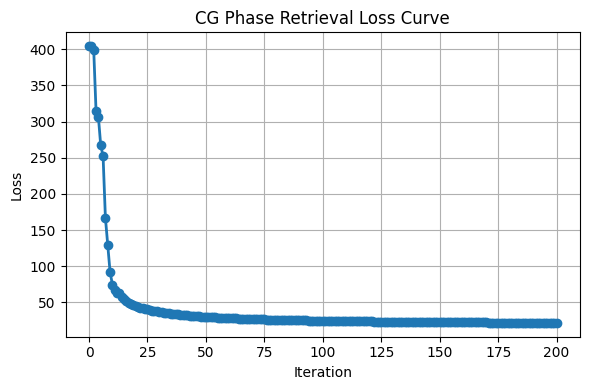

In [1398]:

plt.figure(figsize=(6, 4))
plt.plot(losses, marker='o', linewidth=2)
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("CG Phase Retrieval Loss Curve")
plt.grid(True)
plt.tight_layout()
plt.show()


In [1399]:
print(pad_factor)

8


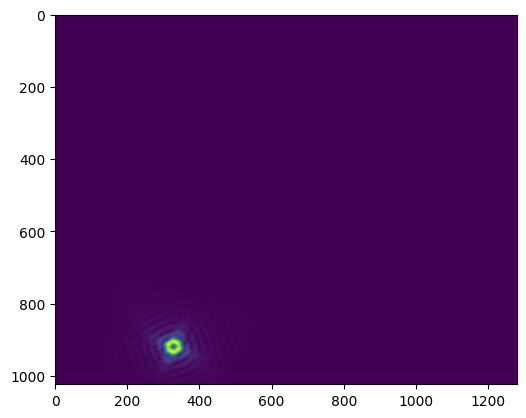

In [1400]:
plt.imshow(A_ff_recon)

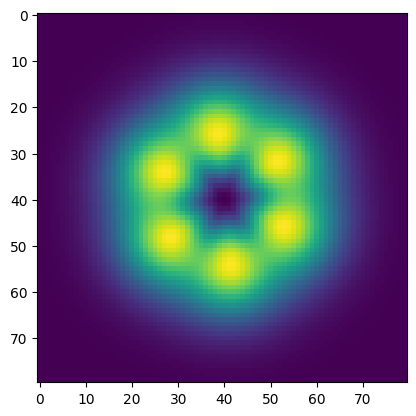

In [1401]:
plt.imshow(A_target[yc-20*2:yc+20*2,xc-20*2:xc+20*2])

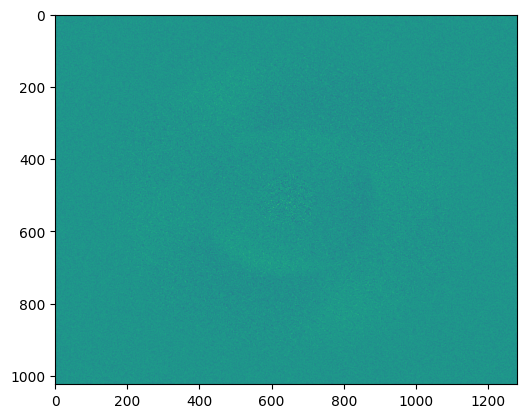

In [1402]:
plt.imshow(phi_recon)

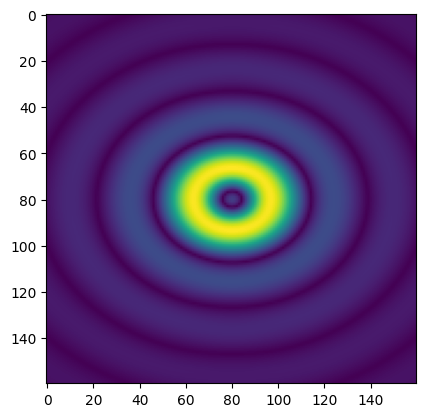

In [1419]:
plt.imshow(get_farfield(phi_bb,pad_factor=8,crop = False)[512*8 - 20*4:512*8 + 20*4,640*8 - 20*4:640*8 + 20*4])

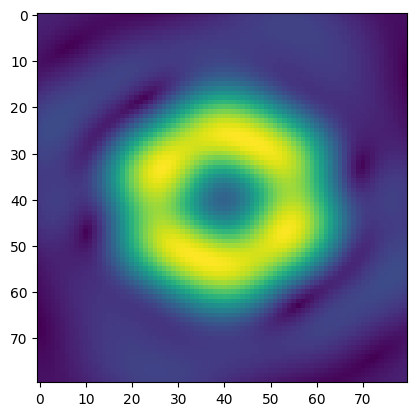

In [1406]:
plt.imshow(get_farfield(torch.tensor(phi_recon),pad_factor=8,crop = False)[yc-20*2:yc+20*2,xc-20*2:xc+20*2])

In [1352]:
def recenter_phase_map(phase, shift_x, shift_y):
    return torch.roll(phase, shifts=(-int(shift_y), -int(shift_x)), dims=(0, 1))

In [985]:
fs.slm.get_source_center(),phi_nf.shape

(array([627.38755535, 500.34136285]), torch.Size([1024, 1280]))

array([[0.57543576, 0.5754358 , 0.57543606, ..., 0.5786537 , 0.5786536 ,
        0.57865363],
       [0.57543564, 0.57543576, 0.5754359 , ..., 0.5786534 , 0.57865345,
        0.57865345],
       [0.5754351 , 0.5754352 , 0.5754354 , ..., 0.57865304, 0.57865304,
        0.57865304],
       ...,
       [0.57453877, 0.574539  , 0.5745396 , ..., 0.57393795, 0.5739384 ,
        0.57393855],
       [0.57453847, 0.57453865, 0.57453924, ..., 0.573938  , 0.5739384 ,
        0.5739386 ],
       [0.5745384 , 0.5745385 , 0.5745391 , ..., 0.57393813, 0.5739384 ,
        0.5739386 ]], dtype=float32)

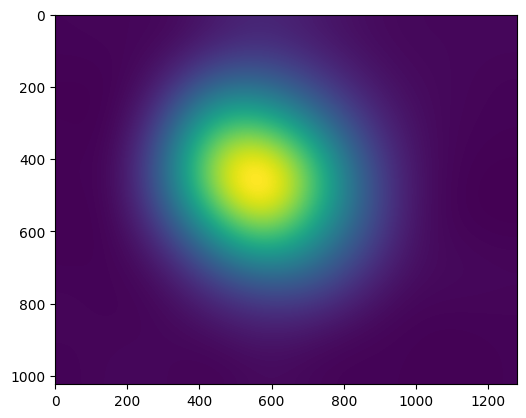

In [816]:
plt.imshow(fs.slm.source['amplitude'])

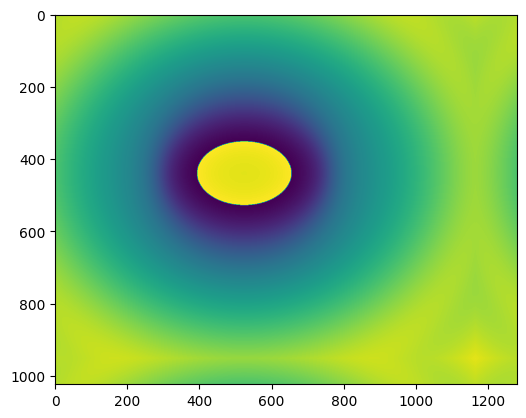

In [ ]:
plt.imshow(recenter_phase_map(phi_nf,512-456,640-568))

In [850]:
def bottle_beam_phase_fit(fs):
    ro = 240
    return np.array([[np.pi if ((i-512)**2 + (j-640)**2) <= ro**2 else 0 for j in range(1280)] for i in range(1024)])


In [851]:
60-fs.slm.get_source_center()[1],fs.slm.get_source_center()[0]

(-440.3413628494446, 627.3875553511883)

writing phase


c:\Users\QC\envs\SLM_new\Lib\site-packages\slmsuite\hardware\slms\slm.py:357: UserWarning:

The backwards-compatible alias SLM.write will be depreciated in favor of SLM.set_phase in a future release.



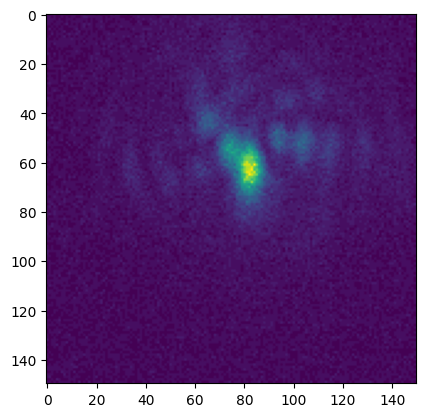

In [1367]:
bb_imgcg = get_cam(fs,phase=phi_recon)
plt.imshow(bb_imgcg[460:610,640:790])

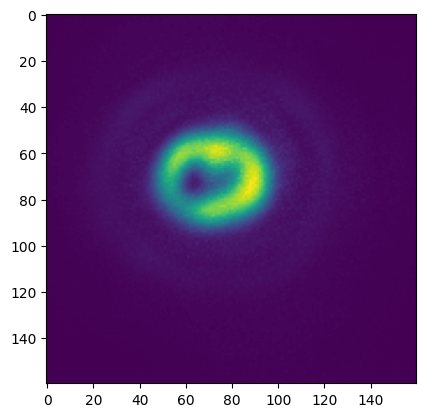

In [1368]:
plt.imshow(bb_imgcg[230-40*2:230+40*2,1180-40*2:1180+40*2])

writing phase


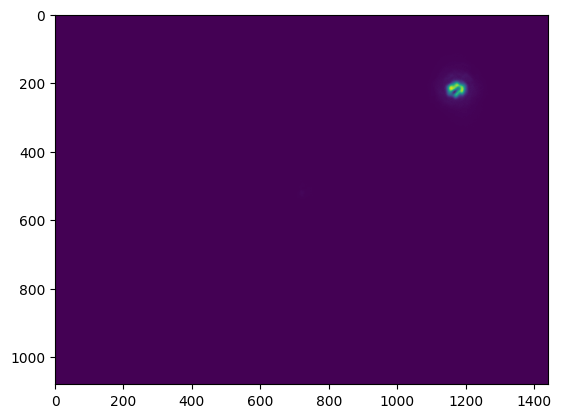

In [1353]:
bb_imggs = get_cam(fs,phase=phi_nf.numpy())
plt.imshow(bb_imggs)

In [ ]:
# np.save(f"{figures_path/'raw'/"periodic_bb_gs500_cam"}.npy", bb_imggs)
# np.save(f"{figures_path/'raw'/"periodic_bb_cg500_cam"}.npy", bb_imgcg)

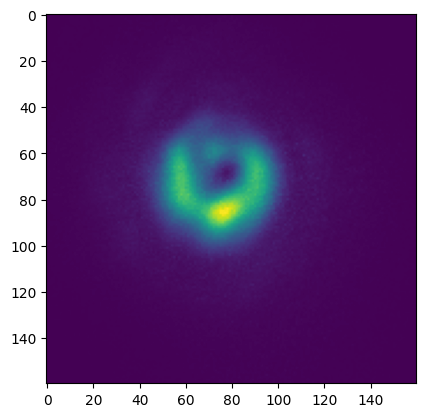

In [1311]:
plt.imshow(bb_imggs[230-40*2:230+40*2,1180-40*2:1180+40*2])

optimised params are [3.06884854e-04 1.41901545e+01 7.99999999e+01 8.00000000e+01
 1.89479248e-03]


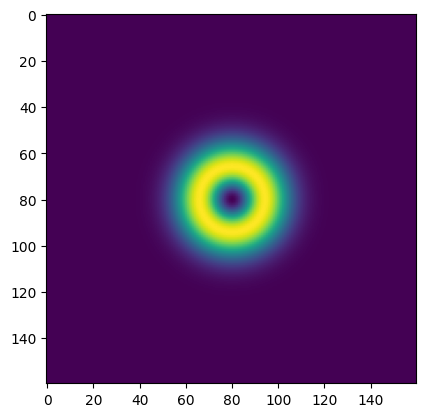

In [1420]:
plot_fit_bb(target = get_farfield(phi_bb,pad_factor=8,crop = False)[512*8 - 20*4:512*8 + 20*4,640*8 - 20*4:640*8 + 20*4])

optimised params are [2.28319016e-03 7.61287379e+00 4.20000202e+01 3.99999947e+01
 1.99229268e-03]


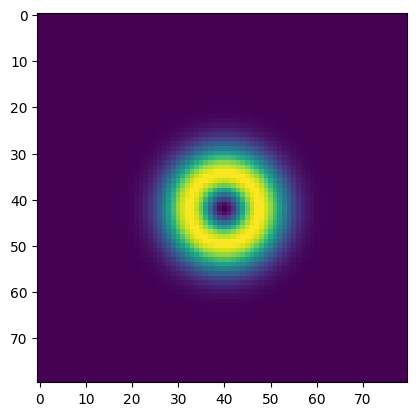

optimised params are [2.38845390e-03 7.44054384e+00 3.99923272e+01 4.00091351e+01
 2.69927691e-03]


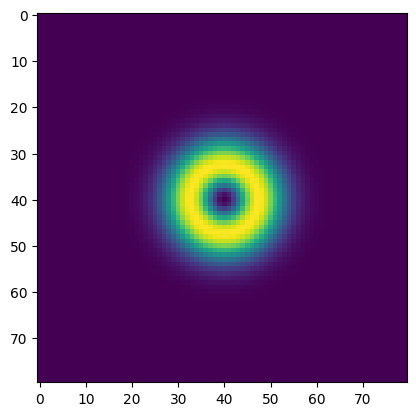

In [1369]:

plot_fit_bb(target = get_farfield(torch.tensor(phi_recon),pad_factor=4,crop = False)[yc-20*2:yc+20*2,xc-20*2:xc+20*2])

optimised params are [ 3.11665311e-04  1.34597453e+01  3.99869255e+01  4.00026935e+01
  3.27955895e-03 -3.40444311e-01]


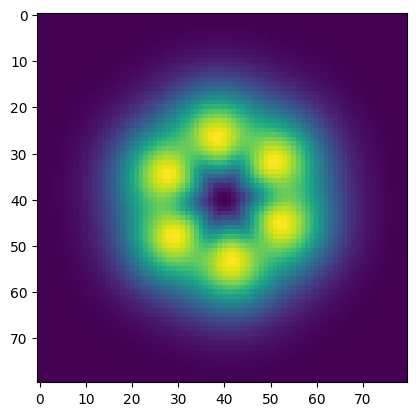

In [1407]:
plot_fit_periodic_bb(get_farfield(torch.tensor(phi_recon),pad_factor=8,crop = False)[yc-20*2:yc+20*2,xc-20*2:xc+20*2])